In [1]:
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')

# Always include the https://  and the final /
path = 'https://github.com/oregon-data-science/DSCI101/raw/main/data/'

'import completed'

'import completed'

## Random selection and simulation

In [2]:
outcomes = make_array('heads', 'tails')

In [3]:
np.random.choice(outcomes)

'heads'

In [4]:
np.random.choice(outcomes, 10)

array(['heads', 'heads', 'tails', 'tails', 'tails', 'tails', 'tails',
       'tails', 'heads', 'tails'],
      dtype='<U5')

In [5]:
np.random.choice(outcomes, 10) == 'heads'

array([ True,  True, False, False,  True,  True, False, False, False,  True], dtype=bool)

In [6]:
sum(np.random.choice(outcomes, 10) == 'heads')

2

In [7]:
sum(np.random.choice(outcomes, 10) == 'tails')

6

In [8]:
flips = np.random.choice(outcomes, 10)

In [9]:
sum(flips == 'heads')

7

In [10]:
sum(flips == 'tails')

3

In [11]:
def heads_in_100_tosses():
    return sum(np.random.choice(outcomes, 100) == 'heads')

In [12]:
results = make_array()

for i in np.arange(10000):
    results = np.append(results, heads_in_100_tosses())
    
results

array([ 46.,  52.,  53., ...,  49.,  52.,  59.])

In [13]:
heads = Table().with_columns('Heads', results)
heads

Heads
46
52
53
50
53
44
60
45
47
56


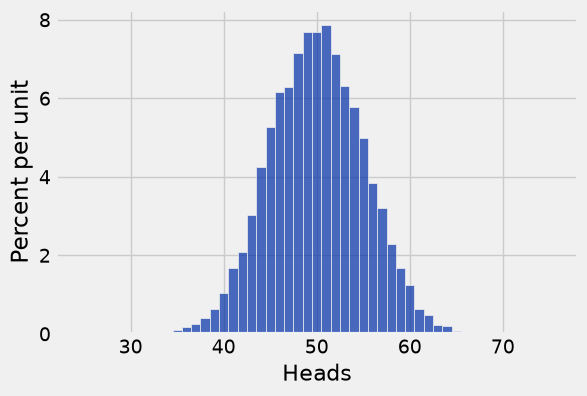

In [14]:
heads.hist('Heads', bins=np.arange(24.5, 76.5))

In [15]:
## back to lecture slides

## Monty Hall

In [ ]:
## let's make a plan of how to simulate many iterations of the gameshow.
## Step 1: 























In [16]:
goats = make_array('first goat', 'second goat')

In [17]:
doors = np.append("car", goats)

In [18]:
doors

array(['car', 'first goat', 'second goat'],
      dtype='<U11')

In [19]:
## simulating contestant choice, there are three identical doors
contestant_choice = np.random.choice(doors)
contestant_choice

'first goat'

In [20]:
## Monty unvails a goat function
def unvail_a_goat(a_goat):
    if a_goat == 'first goat':
        return 'second goat'
    elif a_goat == 'second goat':
        return 'first goat'

In [21]:
unvail_a_goat('first goat')

'second goat'

In [22]:
unvail_a_goat('oxyn bridge')

In [23]:
## a function to create one iternation of the game show

def play_monty_hall():
    
    ## contestant chooses a door
    contestant_choice = np.random.choice(doors)
    
    ## Monty unvails a goat depending on contestant's choice
    # contestant guesses 1st goat
    if contestant_choice == 'first goat':
        monty_choice = 'second goat'
        remaining_door = 'car'
        
    # contestant guesses 2st goat    
    elif contestant_choice == 'second goat':
        monty_choice = 'first goat'
        remaining_door = 'car'
    
    # contestant guesses car
    elif contestant_choice == 'car':
        monty_choice = np.random.choice(goats)
        remaining_door = unvail_a_goat(monty_choice)
        
    # return [contestant's guess, revealed, remaining]
    return [contestant_choice, monty_choice, remaining_door]

In [ ]:
# some individual games

In [24]:
play_monty_hall()

['first goat', 'second goat', 'car']

In [25]:
play_monty_hall()

['car', 'first goat', 'second goat']

In [26]:
play_monty_hall()

['car', 'first goat', 'second goat']

In [27]:
games = Table(['Guess', 'Revealed', 'Remaining'])
games

Guess,Revealed,Remaining


In [28]:
games.append(play_monty_hall())

Guess,Revealed,Remaining
second goat,first goat,car


In [29]:
## let's play a bunch of games
games = Table(['Guess', 'Revealed', 'Remaining'])
for i in np.arange(1000):
    games.append(play_monty_hall())
    
games

Guess,Revealed,Remaining
car,second goat,first goat
second goat,first goat,car
second goat,first goat,car
first goat,second goat,car
second goat,first goat,car
car,first goat,second goat
second goat,first goat,car
first goat,second goat,car
first goat,second goat,car
second goat,first goat,car


In [31]:
games.group('Guess')

Guess,count
car,329
first goat,320
second goat,351


In [32]:
games.group('Revealed')

Revealed,count
first goat,524
second goat,476


In [30]:
games.group('Remaining')

Remaining,count
car,671
first goat,156
second goat,173


In [ ]:
# so should you stay or should you switch?

In [ ]:
## back to lecture slides

## Probability ##

In [ ]:
## I have three cards: ace of hearts, king of diamonds,  and queen of spades.
## I shuffle them and draw two cards at random without  replacement.
## What is the chance that I get the Queen followed by the  King?

In [ ]:
## try by hand:
## AK, AQ, QA, QK(we want), KQ, KA

In [1]:
chance_QK = 1/6

In [ ]:
# not super scalable!

In [ ]:
# first card, A, K or Q(we want)
1/3

In [ ]:
# second card, A or K (we want)
1/2

In [4]:
# multiplication rule (AND)
chance_QK = 1/3 * 1/2
chance_QK

0.16666666666666666

In [ ]:
# back to slides

In [ ]:
# next game
# I have three cards: ace of hearts, king of diamonds, and queen of spades.
# I shuffle them and draw two cards at random without replacement.
# What is the chance that one of the cards I draw is a King and the other is Queen?

In [ ]:
# one way
# A, K, Q(want) 
# A, K(want) 

# second way
# A, K (want), Q 
# A, Q(want) 

In [5]:
1/3*1/2 + 1/3*1/2

0.3333333333333333

In [ ]:
# addition rule (OR)

In [ ]:
## back to slides

# Rick and morty

In [ ]:
# Discussion Question 1:
# P(Rick and Morty both appear)

In [ ]:
# Discussion Question 2
# P(neither Rick nor Morty appears)

In [ ]:
# Discussion Question 3
# P(either Rick or Morty appears)


## Random Sampling ##


In [ ]:
# united flights from 2015
united = Table.read_table(path + 'united.csv')
 # for visualization purposes add a column from 0 to nrow
united = united.with_column('Row', np.arange(united.num_rows)).move_to_start('Row')
united

In [ ]:
## all the flights to JFK, random or deterministic sample?
united.where('Destination', 'JFK') 

In [ ]:
## take each 1000th row, random or deterministic sample?
united.take(np.arange(0, united.num_rows, 1000))

In [ ]:
## deterministic or random? (fill in some numbers)
united.take(make_array(...))

In [ ]:
## next try, step 1, pick a random starting value
start = np.random.choice(np.arange(1000))
start 

In [ ]:
## step 2: starting from your random starting point, pick every 1000th row
our_sample = united.take(np.arange(start, united.num_rows, 1000))

In [ ]:
our_sample.show()

In [ ]:
## is this random?  or deterministic?